In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                              precision_score, recall_score, f1_score, roc_auc_score,
                              roc_curve, log_loss)

plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42          # same seed everywhere, as asked
np.random.seed(RANDOM_STATE)

def plot_cm(cm, title):
    # confusion matrix with Actual on the rows, Predicted on the columns
    disp = ConfusionMatrixDisplay(cm, display_labels=["Benign (0)", "Malignant (1)"])
    disp.plot(cmap="Blues", colorbar=False)
    disp.ax_.set_xlabel("Predicted")
    disp.ax_.set_ylabel("Actual")
    disp.ax_.set_title(title)
    plt.show()

In [2]:
data = load_breast_cancer()
X = data.data
print("Shape:", X.shape, "->", X.shape[0], "samples,", X.shape[1], "features")
print("First 5 feature names:", data.feature_names[:5].tolist())
print("Target names (sklearn order):", data.target_names.tolist())

Shape: (569, 30) -> 569 samples, 30 features
First 5 feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
Target names (sklearn order): ['malignant', 'benign']


In [3]:
# sklearn's own coding is 0 = malignant, 1 = benign - the assignment wants it flipped
print("sklearn coding -> 0 (malignant):", (data.target == 0).sum(),
      " 1 (benign):", (data.target == 1).sum())

y = 1 - data.target     # now 1 = malignant, 0 = benign
print("after relabel   -> malignant (1):", (y == 1).sum(), " benign (0):", (y == 0).sum())
assert (y == 1).sum() == 212

sklearn coding -> 0 (malignant): 212  1 (benign): 357
after relabel   -> malignant (1): 212  benign (0): 357


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("training samples:", len(X_train))
print("test samples    :", len(X_test))
print("positives (malignant) in test set:", y_test.sum())

training samples: 455
test samples    : 114
positives (malignant) in test set: 42


In [5]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)     # fit on train only
X_test_s = scaler.transform(X_test)           # reuse the train mean/std

print("before scaling: mean area in [", X_train[:, 3].min(), ",", X_train[:, 3].max(), "]")
print("before scaling: mean smoothness in [", X_train[:, 4].min(),
      ",", X_train[:, 4].max(), "]")
print("after scaling, train mean (first 3 features):", X_train_s.mean(axis=0)[:3].round(3))
print("after scaling, train std  (first 3 features):", X_train_s.std(axis=0)[:3].round(3))

before scaling: mean area in [ 143.5 , 2501.0 ]
before scaling: mean smoothness in [ 0.06251 , 0.1634 ]
after scaling, train mean (first 3 features): [-0.  0. -0.]
after scaling, train std  (first 3 features): [1. 1. 1.]


first 5 probabilities: [0.    1.    0.043 0.576 0.509]
first 5 predictions  : [0 1 0 1 1]
training accuracy: 0.9868
test accuracy    : 0.9649


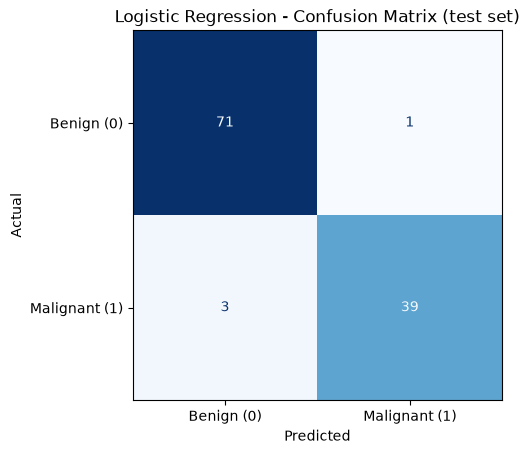

In [6]:
# lbfgs solver (sklearn default), L2 penalty, C = 1.0;
# max_iter bumped up so it actually converges
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_s, y_train)

lr_pred = log_reg.predict(X_test_s)                # labels at threshold 0.5
lr_prob = log_reg.predict_proba(X_test_s)[:, 1]    # P(malignant)

print("first 5 probabilities:", lr_prob[:5].round(3))
print("first 5 predictions  :", lr_pred[:5])
print("training accuracy:", round(log_reg.score(X_train_s, y_train), 4))
print("test accuracy    :", round(accuracy_score(y_test, lr_pred), 4))

lr_cm = confusion_matrix(y_test, lr_pred)
plot_cm(lr_cm, "Logistic Regression - Confusion Matrix (test set)")

In [7]:
tn, fp, fn, tp = lr_cm.ravel()
print(f"TP={tp}  FP={fp}  TN={tn}  FN={fn}")
print(f"precision = TP/(TP+FP) = {tp}/{tp+fp} = {tp/(tp+fp):.4f}")
print(f"recall    = TP/(TP+FN) = {tp}/{tp+fn} = {tp/(tp+fn):.4f}")
print("(check) sklearn precision:", round(precision_score(y_test, lr_pred), 4),
      " recall:", round(recall_score(y_test, lr_pred), 4))

auc_lr = roc_auc_score(y_test, lr_prob)
print("ROC-AUC:", round(auc_lr, 4))

TP=39  FP=1  TN=71  FN=3
precision = TP/(TP+FP) = 39/40 = 0.9750
recall    = TP/(TP+FN) = 39/42 = 0.9286
(check) sklearn precision: 0.975  recall: 0.9286
ROC-AUC: 0.996


In [8]:
actual = np.array([1, 1, 0, 1, 0, 1, 0, 0, 1, 0])
proba  = np.array([0.95, 0.80, 0.70, 0.60, 0.55, 0.45, 0.40, 0.30, 0.20, 0.10])

for t in [0.50, 0.30]:
    pred_t = (proba >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(actual, pred_t).ravel()
    print(f"t = {t}")
    print("  predicted:", pred_t.tolist())
    print(f"  TP={tp_} FP={fp_} TN={tn_} FN={fn_}")
    print(f"  precision = {tp_}/{tp_+fp_} = {tp_/(tp_+fp_):.2f} ",
          f"  recall = {tp_}/{tp_+fn_} = {tp_/(tp_+fn_):.2f}")

t = 0.5
  predicted: [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
  TP=3 FP=2 TN=3 FN=2
  precision = 3/5 = 0.60    recall = 3/5 = 0.60
t = 0.3
  predicted: [1, 1, 1, 1, 1, 1, 1, 1, 0, 0]
  TP=4 FP=4 TN=1 FN=1
  precision = 4/8 = 0.50    recall = 4/5 = 0.80


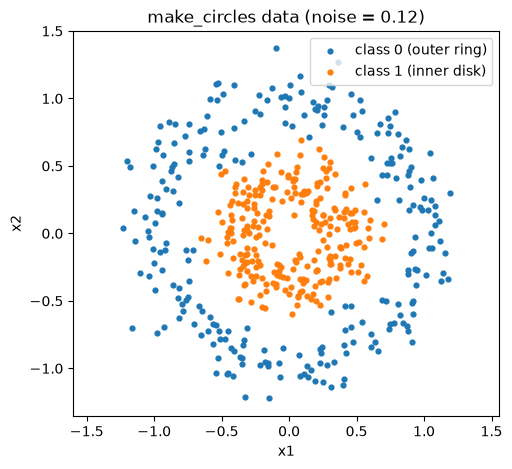

(i)  test accuracy on raw (x1, x2): 0.45
(ii) test accuracy with x1^2, x2^2, x1*x2 added: 0.98
weights (x1, x2, x1^2, x2^2, x1*x2): [[ 0.19  0.05 -5.78 -6.03  0.01]]


In [9]:
Xc, yc = make_circles(n_samples=500, noise=0.12, factor=0.4, random_state=RANDOM_STATE)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=RANDOM_STATE)

plt.figure(figsize=(5.5, 5))
plt.scatter(Xc[yc == 0, 0], Xc[yc == 0, 1], s=12, label="class 0 (outer ring)")
plt.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=12, label="class 1 (inner disk)")
plt.title("make_circles data (noise = 0.12)"); plt.xlabel("x1"); plt.ylabel("x2")
plt.legend(); plt.axis("equal"); plt.show()

# (i) raw features
lr_raw = LogisticRegression(random_state=RANDOM_STATE).fit(Xc_train, yc_train)
acc_raw = lr_raw.score(Xc_test, yc_test)
print("(i)  test accuracy on raw (x1, x2):", round(acc_raw, 4))

# (ii) add x1^2, x2^2, x1*x2
def add_poly(A):
    return np.column_stack([A, A[:, 0] ** 2, A[:, 1] ** 2, A[:, 0] * A[:, 1]])

lr_poly = LogisticRegression(random_state=RANDOM_STATE).fit(add_poly(Xc_train), yc_train)
acc_poly = lr_poly.score(add_poly(Xc_test), yc_test)
print("(ii) test accuracy with x1^2, x2^2, x1*x2 added:", round(acc_poly, 4))
print("weights (x1, x2, x1^2, x2^2, x1*x2):", lr_poly.coef_.round(2))

first 5 decision scores: [-4.616 12.112 -1.623 -0.345 -0.175]
first 5 predictions    : [0 1 0 0 0]
training accuracy: 0.989
test accuracy    : 0.9649


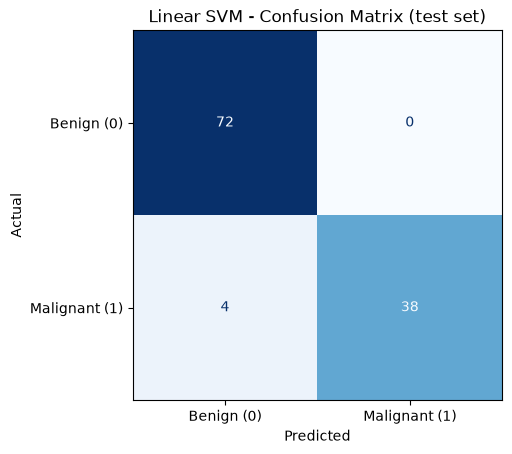


note: decision_function gives w.x + b, any real number -
it isn't bounded in [0,1] and isn't calibrated, so it should never
be read as P(malignant), only its sign and rough size.


In [10]:
svm = SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE)
svm.fit(X_train_s, y_train)

svm_pred = svm.predict(X_test_s)
svm_score = svm.decision_function(X_test_s)
# ^ signed distance from the hyperplane, not a probability

print("first 5 decision scores:", svm_score[:5].round(3))
print("first 5 predictions    :", svm_pred[:5])
print("training accuracy:", round(svm.score(X_train_s, y_train), 4))
print("test accuracy    :", round(accuracy_score(y_test, svm_pred), 4))

svm_cm = confusion_matrix(y_test, svm_pred)
plot_cm(svm_cm, "Linear SVM - Confusion Matrix (test set)")

print("\nnote: decision_function gives w.x + b, any real number -")
print("it isn't bounded in [0,1] and isn't calibrated, so it should never")
print("be read as P(malignant), only its sign and rough size.")

In [11]:
tn_s, fp_s, fn_s, tp_s = svm_cm.ravel()
print(f"TP={tp_s}  FP={fp_s}  TN={tn_s}  FN={fn_s}")
print("precision:", round(precision_score(y_test, svm_pred), 4))
print("recall   :", round(recall_score(y_test, svm_pred), 4))

auc_svm = roc_auc_score(y_test, svm_score)
print("ROC-AUC:", round(auc_svm, 4))

TP=38  FP=0  TN=72  FN=4
precision: 1.0
recall   : 0.9048
ROC-AUC: 0.9914


       C  margin width  train acc  test acc
   0.001        6.0855     0.9429    0.9211
   0.010        2.8782     0.9692    0.9561
   0.100        1.4572     0.9824    0.9825
   1.000        0.7359     0.9890    0.9649
  10.000        0.2390     0.9956    0.9737
 100.000        0.0915     0.9978    0.9298
1000.000        0.0420     1.0000    0.9035


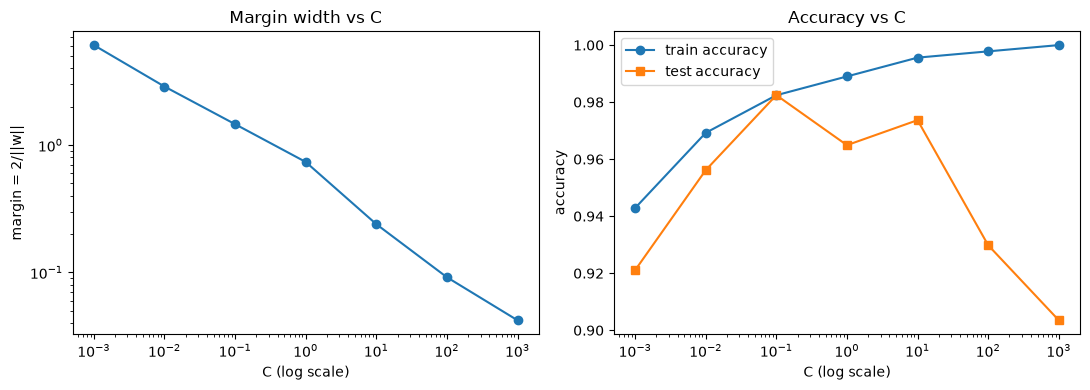

In [12]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
rows = []
for C in C_values:
    m = SVC(kernel="linear", C=C, random_state=RANDOM_STATE).fit(X_train_s, y_train)
    rows.append([C, 2 / np.linalg.norm(m.coef_),
                 m.score(X_train_s, y_train), m.score(X_test_s, y_test)])
c_df = pd.DataFrame(rows, columns=["C", "margin width", "train acc", "test acc"])
print(c_df.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(c_df["C"], c_df["margin width"], "o-")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_title("Margin width vs C")
ax[0].set_xlabel("C (log scale)"); ax[0].set_ylabel("margin = 2/||w||")

ax[1].plot(c_df["C"], c_df["train acc"], "o-", label="train accuracy")
ax[1].plot(c_df["C"], c_df["test acc"], "s-", label="test accuracy")
ax[1].set_xscale("log"); ax[1].set_title("Accuracy vs C"); ax[1].set_xlabel("C (log scale)")
ax[1].set_ylabel("accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

SVM (hinge loss) on the training set:
  mean hinge loss: 0.0372
  points with hinge loss exactly 0 (margin >= 1): 428 of 455
  misclassified points (margin <= 0): 5
Logistic Regression (log-loss) on the training set:
  mean log-loss: 0.0532  (sklearn check: 0.0532 )
  points with log-loss exactly 0: 0
number of SVM support vectors: 38


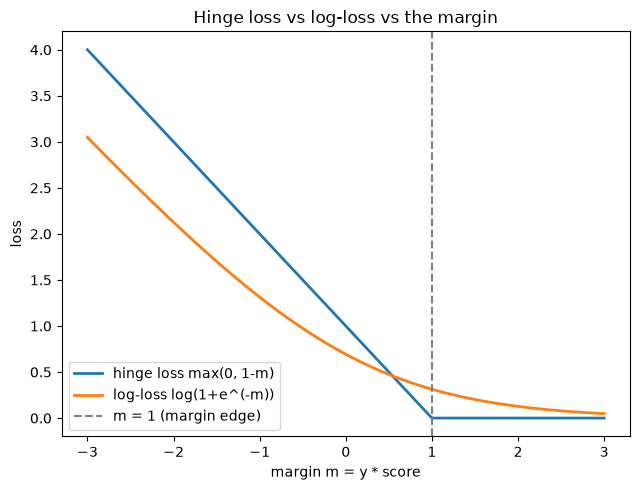

In [13]:
y_pm = np.where(y_train == 1, 1, -1)                      # {-1, +1} coding for the margin
svm_margin = y_pm * svm.decision_function(X_train_s)
lr_margin  = y_pm * log_reg.decision_function(X_train_s)  # raw linear score before the sigmoid

hinge = np.maximum(0, 1 - svm_margin)
logl  = np.log1p(np.exp(-lr_margin))

print("SVM (hinge loss) on the training set:")
print("  mean hinge loss:", round(hinge.mean(), 4))
print("  points with hinge loss exactly 0 (margin >= 1):",
      (hinge == 0).sum(), "of", len(hinge))
print("  misclassified points (margin <= 0):", (svm_margin <= 0).sum())
print("Logistic Regression (log-loss) on the training set:")
print("  mean log-loss:", round(logl.mean(), 4), " (sklearn check:",
      round(log_loss(y_train, log_reg.predict_proba(X_train_s)), 4), ")")
print("  points with log-loss exactly 0:", (logl == 0).sum())
print("number of SVM support vectors:", svm.n_support_.sum())

m = np.linspace(-3, 3, 300)
plt.figure(figsize=(6.5, 5))
plt.plot(m, np.maximum(0, 1 - m), label="hinge loss max(0, 1-m)", lw=2)
plt.plot(m, np.log1p(np.exp(-m)), label="log-loss log(1+e^(-m))", lw=2)
plt.axvline(1, color="gray", ls="--", label="m = 1 (margin edge)")
plt.xlabel("margin m = y * score"); plt.ylabel("loss")
plt.title("Hinge loss vs log-loss vs the margin"); plt.legend(); plt.tight_layout(); plt.show()

In [14]:
for name, pred in [("Logistic Regression", lr_pred), ("Linear SVM", svm_pred)]:
    print(name)
    print(confusion_matrix(y_test, pred))
    print(f"  precision={precision_score(y_test, pred):.4f} ",
          f" recall={recall_score(y_test, pred):.4f}")
    print(f"  accuracy={accuracy_score(y_test, pred):.4f} ",
          f" F1={f1_score(y_test, pred):.4f}")
    print()

Logistic Regression
[[71  1]
 [ 3 39]]
  precision=0.9750   recall=0.9286
  accuracy=0.9649   F1=0.9512

Linear SVM
[[72  0]
 [ 4 38]]
  precision=1.0000   recall=0.9048
  accuracy=0.9649   F1=0.9500



In [15]:
def summary(pred, score):
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred).ravel()
    return [f"{tp_} / {fp_} / {tn_} / {fn_}",
            round(precision_score(y_test, pred), 4), round(recall_score(y_test, pred), 4),
            round(accuracy_score(y_test, pred), 4), round(roc_auc_score(y_test, score), 4)]

comparison = pd.DataFrame({"Logistic Regression": summary(lr_pred, lr_prob),
                            "Linear SVM": summary(svm_pred, svm_score)},
                           index=["TP / FP / TN / FN", "Precision",
                                  "Recall", "Accuracy", "ROC-AUC"])
comparison.index.name = "Metric"
comparison

,Logistic Regression,Linear SVM
Metric,,
TP / FP / TN / FN,39 / 1 / 71 / 3,38 / 0 / 72 / 4
Precision,0.975,1.0
Recall,0.9286,0.9048
Accuracy,0.9649,0.9649
ROC-AUC,0.996,0.9914


 threshold  TP  FP  TN  FN  precision  recall    FPR    TPR
       0.3  41   1  71   1     0.9762  0.9762 0.0139 0.9762
       0.5  39   1  71   3     0.9750  0.9286 0.0139 0.9286
       0.7  38   0  72   4     1.0000  0.9048 0.0000 0.9048


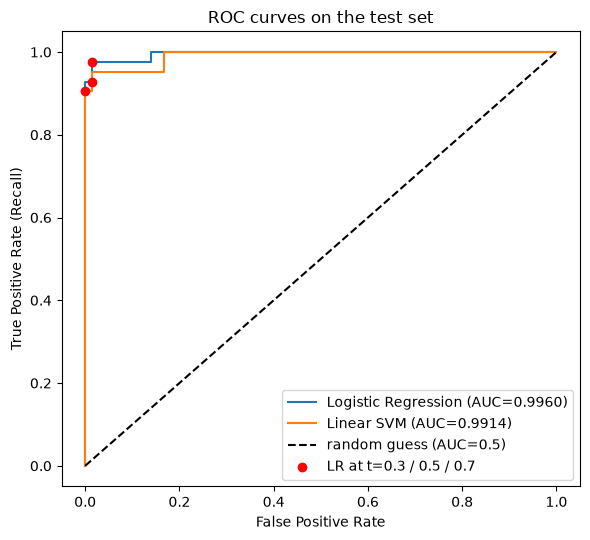

In [16]:
rows = []
for t in [0.30, 0.50, 0.70]:
    pred_t = (lr_prob >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred_t).ravel()
    rows.append([t, tp_, fp_, tn_, fn_, tp_/(tp_+fp_), tp_/(tp_+fn_),
                 fp_/(fp_+tn_), tp_/(tp_+fn_)])
thr_df = pd.DataFrame(rows, columns=["threshold", "TP", "FP", "TN", "FN",
                                      "precision", "recall", "FPR", "TPR"])
print(thr_df.round(4).to_string(index=False))

fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_score)

plt.figure(figsize=(6, 5.5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={auc_lr:.4f})")
plt.plot(fpr_svm, tpr_svm, label=f"Linear SVM (AUC={auc_svm:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="random guess (AUC=0.5)")
plt.scatter(thr_df["FPR"], thr_df["TPR"], color="red", zorder=3,
            label="LR at t=0.3 / 0.5 / 0.7")
plt.title("ROC curves on the test set")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()